# LAB 01 — Khám phá và chuẩn bị dữ liệu Student Performance Factors

**DNU Learning Analytics Lab**

- **Họ tên:** Đỗ Thanh Dũng
- **MSSV:** 1871020163
- **Lớp:** CNTT 18-02

> **Câu hỏi trung tâm:** Dataset này có đủ hiểu, đủ sạch và đủ phù hợp để bắt đầu modeling chưa?


## Environment checkpoint

Chạy cell dưới đây. Nếu không có lỗi import, môi trường đã sẵn sàng cho bài lab.


In [8]:
import os

# Lọc bỏ thư mục Prolog khỏi đường dẫn hệ thống của Python
os.environ["PATH"] = ";".join(
    [p for p in os.environ["PATH"].split(";") if "ProLog_TTNT" not in p]
)

# Sau đó tiến hành import thư viện bình thường
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Đã loại bỏ xung đột DLL thành công!")

Đã loại bỏ xung đột DLL thành công!


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Environment ready!")
print("pandas:", pd.__version__)


Environment ready!
pandas: 3.0.3


In [10]:
from pathlib import Path
from urllib.request import urlopen

URL = "https://raw.githubusercontent.com/hsmanik/Student_performance_factors/main/StudentPerformanceFactors.csv"
DEST = Path("data/StudentPerformanceFactors.csv")

DEST.parent.mkdir(parents=True, exist_ok=True)

if DEST.exists() and DEST.stat().st_size > 1000:
    print(f"Dataset already exists: {DEST}")
else:
    print("Downloading Student Performance Factors dataset...")
    with urlopen(URL, timeout=30) as response:
        DEST.write_bytes(response.read())
    print(f"Saved dataset to {DEST} ({DEST.stat().st_size:,} bytes)")
    

Dataset already exists: data\StudentPerformanceFactors.csv


# Mission 1 — Understand the dataset

## Nhiệm vụ

1. Đọc file `data/StudentPerformanceFactors.csv`.
2. Quan sát các dòng đầu tiên.
3. Kiểm tra kích thước dataset.
4. Kiểm tra kiểu dữ liệu và non-null count.
5. Trả lời bằng Markdown:
   - Một row đại diện cho đối tượng nào?
   - Dataset có bao nhiêu samples và variables?
   - Target gốc là cột nào?
   - Nếu dự đoán trực tiếp target này, đây là regression hay classification?


In [11]:
# Đọc dữ liệu bằng đường dẫn tương đối
df = pd.read_csv("data/StudentPerformanceFactors.csv")

# Khám phá sơ bộ
display(df.head())
print("Shape:", df.shape)
df.info()


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


Shape: (6607, 20)
<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null   int64
 6   Previous_Scores             6607 non-null   int64
 7   Motivation_Level            6607 non-null   str  
 8   Internet_Access             6607 non-null   str  
 9   Tutoring_Sessions           6607 non-null   int64
 10  Family_Income               6607 non-null   str  
 11  Teacher_Quality             6529 non-null   str  
 12  School_Type                 6607 non-null   str  
 13  Peer_Influence              6607 non-null   str  
 14  P

### Kết luận Mission 1

- Một row đại diện cho: Một  sinh viên cụ thể
- Số samples: 6607
- Số variables: 20
- Target gốc: Exam_Score
- Dạng bài toán nếu dự đoán trực tiếp target: Regression

**Giải thích ngắn:**  
Dataset bao gồm 6607 bản ghi tương ứng với học sinh và 20 thuộc tính mô tả các yếu tố ảnh hưởng đến học tập. Biến mục tiêu Exam_Score là một giá trị số liên tục, do đó nếu xây dựng mô hình dự đoán trực tiếp giá trị này, chúng ta sẽ giải quyết bài toán hồi quy (Regression)


# Mission 2 — Build a data dictionary

Pandas dtype cho biết cách máy đang lưu dữ liệu, nhưng không phải lúc nào cũng phản ánh đầy đủ **ý nghĩa dữ liệu**.

Hãy phân loại các cột thành:

- numerical;
- categorical;
- ordinal categorical;
- target.

Tạo một bảng Data Dictionary có tối thiểu các cột:

| Variable | Ý nghĩa | Pandas dtype | Semantic type | Vai trò dự kiến |
|---|---|---|---|---|


In [12]:
# Gợi ý: xác định nhanh nhóm cột theo dtype
numeric_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numeric columns:")
print(numeric_cols)

print("\nCategorical-like columns:")
print(categorical_cols)


Numeric columns:
['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity', 'Exam_Score']

Categorical-like columns:
['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']


C:\Users\Do Thanh Dung\AppData\Local\Temp\ipykernel_17960\2809185964.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()


### Data Dictionary

Hoàn thiện bảng cho **tất cả các biến** trong dataset.

| Variable | Ý nghĩa | Pandas dtype | Semantic type | Vai trò dự kiến |
| :--- | :--- | :--- | :--- | :--- |
| **Hours_Studied** | Số giờ học mỗi tuần | int64 / float64 | Numerical | Input feature |
| **Attendance** | Tỷ lệ tham gia lớp học (%) | int64 / float64 | Numerical | Input feature |
| **Sleep_Hours** | Số giờ ngủ trung bình mỗi đêm | int64 / float64 | Numerical | Input feature |
| **Previous_Scores** | Điểm số các bài kiểm tra trước | int64 / float64 | Numerical | Input feature |
| **Tutoring_Sessions** | Số buổi học thêm mỗi tháng | int64 / float64 | Numerical | Input feature |
| **Physical_Activity** | Thời gian hoạt động thể chất | int64 / float64 | Numerical | Input feature |
| **Parental_Involvement** | Mức độ quan tâm của phụ huynh | object | Ordinal categorical | Input feature |
| **Access_to_Resources** | Mức độ tiếp cận tài nguyên học tập | object | Ordinal categorical | Input feature |
| **Extracurricular_Activities** | Tham gia hoạt động ngoại khóa | object | Categorical | Input feature |
| **Motivation_Level** | Mức độ động lực học tập | object | Ordinal categorical | Input feature |
| **Internet_Access** | Có truy cập internet hay không | object | Categorical | Input feature |
| **Family_Income** | Mức thu nhập của gia đình | object | Ordinal categorical | Input feature |
| **Teacher_Quality** | Chất lượng giáo viên | object | Ordinal categorical | Input feature |
| **School_Type** | Loại trường học (Công lập/Tư thục) | object | Categorical | Input feature |
| **Peer_Influence** | Mức độ ảnh hưởng từ bạn bè | object | Categorical | Input feature |
| **Learning_Disabilities** | Có khuyết tật học tập hay không | object | Categorical | Input feature |
| **Parental_Education_Level**| Trình độ học vấn của phụ huynh | object | Ordinal categorical | Input feature |
| **Distance_from_Home** | Khoảng cách từ nhà đến trường | object | Ordinal categorical | Input feature |
| **Gender** | Giới tính của học sinh | object | Categorical | Input feature |
| **Exam_Score** | Điểm số kỳ thi cuối kỳ | float64 | Target | Target |
### Câu hỏi tư duy

1. Có cột nào Pandas đọc là `object` nhưng về ý nghĩa lại có thứ tự không?
2. Tại sao phân biệt này quan trọng khi chuẩn bị dữ liệu cho machine learning?

Trả lời câu 1: Có. Các cột như Motivation_Level (Low, Medium, High), Parental_Involvement (Low, Medium, High), Access_to_Resources (Low, Medium, High), hoặc Parental_Education_Level (High School, College, Postgraduate) bị Pandas hiểu nhầm là chuỗi ký tự (object), nhưng thực chất chúng là các biến phân loại có thứ tự tăng/giảm rõ rệt (Ordinal Categorical).

Trả lời câu 2: Việc phân biệt rõ giúp chúng ta chọn đúng phương pháp mã hóa (encoding):
- Giúp ta chọn phương pháp mã hóa (encoding) chính xác: Dùng Ordinal Encoding (gán giá trị số có thứ tự như 1, 2, 3) cho các biến có thứ tự để giữ nguyên quan hệ hơn/kém; và dùng One-Hot Encoding cho các biến phân loại thông thường.
- Tránh làm mô hình máy học hiểu lầm sai lệch về mặt toán học (ví dụ ép các mức độ thành các khoảng cách số học không đúng bản chất), từ đó giúp cải thiện độ chính xác khi dự đoán điểm số (Exam_Score).

`


# Mission 3 — Data Quality Audit

## Câu hỏi

Dataset có các vấn đề nào sau đây không?

- missing values;
- duplicated rows;
- kiểu dữ liệu bất hợp lý;
- category không nhất quán;
- giá trị số bất thường;
- target không hợp lệ.

Hãy **kiểm tra trước khi xử lý**.


In [13]:
# 1. Missing values
missing = df.isna().sum().sort_values(ascending=False)
display(missing[missing > 0])

# 2. Duplicates
print("Duplicated rows:", df.duplicated().sum())

# 3. Thống kê mô tả
display(df.describe(include="all").T)


Parental_Education_Level    90
Teacher_Quality             78
Distance_from_Home          67
dtype: int64

Duplicated rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Hours_Studied,6607.0,NaN,NaN,NaN,19.975329,5.990594,1.0,16.0,20.0,24.0,44.0
Attendance,6607.0,NaN,NaN,NaN,79.977448,11.547475,60.0,70.0,80.0,90.0,100.0
Parental_Involvement,6607,3,Medium,3362,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Access_to_Resources,6607,3,Medium,3319,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Extracurricular_Activities,6607,2,Yes,3938,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sleep_Hours,6607.0,NaN,NaN,NaN,7.02906,1.46812,4.0,6.0,7.0,8.0,10.0
Previous_Scores,6607.0,NaN,NaN,NaN,75.070531,14.399784,50.0,63.0,75.0,88.0,100.0
Motivation_Level,6607,3,Medium,3351,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Internet_Access,6607,2,Yes,6108,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tutoring_Sessions,6607.0,NaN,NaN,NaN,1.493719,1.23057,0.0,1.0,1.0,2.0,8.0


In [14]:
# 4. Quan sát các giá trị của biến categorical
for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))



--- Parental_Involvement ---
Parental_Involvement
Medium    3362
High      1908
Low       1337
Name: count, dtype: int64

--- Access_to_Resources ---
Access_to_Resources
Medium    3319
High      1975
Low       1313
Name: count, dtype: int64

--- Extracurricular_Activities ---
Extracurricular_Activities
Yes    3938
No     2669
Name: count, dtype: int64

--- Motivation_Level ---
Motivation_Level
Medium    3351
Low       1937
High      1319
Name: count, dtype: int64

--- Internet_Access ---
Internet_Access
Yes    6108
No      499
Name: count, dtype: int64

--- Family_Income ---
Family_Income
Low       2672
Medium    2666
High      1269
Name: count, dtype: int64

--- Teacher_Quality ---
Teacher_Quality
Medium    3925
High      1947
Low        657
NaN         78
Name: count, dtype: int64

--- School_Type ---
School_Type
Public     4598
Private    2009
Name: count, dtype: int64

--- Peer_Influence ---
Peer_Influence
Positive    2638
Neutral     2592
Negative    1377
Name: count, dtype: int6

### Data Quality Report — trước khi cleaning

| Vấn đề | Có/Không | Bằng chứng | Mức độ cần xử lý |
|---|---|---|---|
| Missing values | Có | Các cột Teacher_Quality, Parental_Education_Level, và Distance_from_Home có chứa giá trị NaN (thiếu 67–90 dòng) | Trung bình |
| Duplicates | Không | Số lượng dòng trùng lặp (Duplicated rows) = 0 | Thấp / Không cần |
| Kiểu dữ liệu bất hợp lý | Có | Các biến phân loại có thứ tự (như Motivation_Level, Parental_Involvement) đang nhận kiểu object thay vì ordinal. | Thấp |
| Category không nhất quán | Không | Các giá trị phân loại (như School_Type, Gender, Peer_Influence) rõ ràng, không bị lỗi ký tự hay viết hoa/thường lộn xộn. | Thấp / Không cần |
| Giá trị số đáng ngờ | Không | Thống kê mô tả (describe) cho thấy các cột số như Hours_Studied, Attendance, Exam_Score đều nằm trong giới hạn thực tế, không có giá trị âm hay ngoại lai vô lý. | Thấp / Không cần |

**Nhận xét:**  
Dataset nhìn chung có chất lượng khá tốt, cấu trúc dữ liệu ổn định với 6,607 dòng và không phát hiện dòng trùng lặp nào. Tuy nhiên, dữ liệu vẫn tồn tại một số giá trị bị thiếu (missing values) rải rác ở một vài cột thông tin của phụ huynh và giáo viên, cần được xử lý (imputation hoặc loại bỏ) trước khi đưa vào mô hình. Ngoài ra, các biến dạng chữ (object) cần được định hình lại và mã hóa đúng bản chất ngữ nghĩa để đảm bảo hiệu quả tối ưu cho các thuật toán học máy


# Mission 4 — Investigate suspicious data

Không phải dữ liệu “lạ” nào cũng là dữ liệu “sai”.

## Nhiệm vụ

1. Kiểm tra min/max của `Exam_Score`.
2. Nếu có giá trị vượt ngoài khoảng mà bạn cho là hợp lý, tìm record đó.
3. Không xóa ngay.
4. Trả lời:
   - Đây có phải outlier không?
   - Có đủ bằng chứng để gọi đây là lỗi dữ liệu không?
   - Bạn sẽ giữ, xóa, cap hay kiểm tra nguồn trước? Vì sao?


In [15]:
# Điều tra Exam_Score
display(df["Exam_Score"].describe())

# Viết điều kiện lọc phù hợp để xem record đáng ngờ
# Ví dụ: df[ ... ]


count    6607.000000
mean       67.235659
std         3.890456
min        55.000000
25%        65.000000
50%        67.000000
75%        69.000000
max       101.000000
Name: Exam_Score, dtype: float64

### Kết luận Mission 4

**Quan sát:** Cột Exam_Score có giá trị lớn nhất (max) là 101.0, vượt quá ngưỡng điểm tối đa thông thường là 100.

**Quyết định đề xuất:** Giữ lại giá trị này (hoặc có thể hiệu chỉnh giới hạn về 100 tùy theo nghiệp vụ), vì đây có thể là điểm thưởng hoặc lỗi nhập liệu nhỏ không ảnh hưởng lớn đến phân phối chung.

**Lý do:** 
- Theo nguyên tắc phân tích dữ liệu, Outlier chưa chắc là Error (giá trị ngoại lai không đồng nghĩa với lỗi dữ liệu).
- Giá trị 101 chỉ lệch rất ít so với mốc 100 (tập dữ liệu có tới 6,607 mẫu), việc xóa hoặc đánh dấu lỗi quá gắt gao có thể làm mất thông tin thực tế của học sinh (như điểm cộng thêm).
- Do đó, ta quyết định kiểm tra nguồn/ngữ cảnh và giữ lại hoặc giới hạn (clip) giá trị này về mức tối đa 100 để đảm bảo tính hợp lệ cho mô hình hồi quy sau này.

> Nhớ: Outlier ≠ Error.


# Mission 5 — Handle missing values

## Nhiệm vụ

Với từng cột có missing values:

1. Xác định semantic type.
2. Đề xuất một chiến lược xử lý.
3. Giải thích vì sao.
4. Tạo `df_clean` từ `df.copy()` rồi thực hiện lựa chọn của bạn.

Các lựa chọn có thể cân nhắc:

- loại bỏ record;
- điền mode;
- tạo category `Unknown`;
- hoặc giữ missing để xử lý trong pipeline sau.

Không có một đáp án mặc định cho mọi cột.


In [18]:
df_clean = df.copy()

# Sửa lại cách điền giá trị thiếu để tránh lỗi ChainedAssignmentError
for col in [
    "Teacher_Quality",
    "Parental_Education_Level",
    "Distance_from_Home",
]:
  most_frequent_value = df_clean[col].mode()[0]
  df_clean[col] = df_clean[col].fillna(most_frequent_value)

print("Missing values after your processing:")
display(df_clean.isna().sum()[df_clean.isna().sum() > 0])

Missing values after your processing:


Series([], dtype: int64)

### Giải thích chiến lược xử lý missing

| Cột | Chiến lược | Lý do |
|---|---|---|
| `Teacher_Quality` | Điền bằng giá trị phổ biến nhất (Mode imputation) | Đây là biến phân loại, số lượng thiếu ít (78 dòng) nên dùng giá trị xuất hiện nhiều nhất giúp giữ nguyên phân phối mà không làm thay đổi bản chất dữ liệu. |
| `Parental_Education_Level` | Điền bằng giá trị phổ biến nhất (Mode imputation) | Là biến cấp bậc phân loại với tỷ lệ thiếu thấp, việc gán giá trị chiếm đa số giúp bảo toàn số lượng mẫu học sinh thay vì phải xóa bản ghi. |
| `Distance_from_Home` | Điền bằng giá trị phổ biến nhất (Mode imputation) | Đảm bảo tính nhất quán cho các biến định tính, tránh làm mất mát thông tin quan trọng phục vụ cho việc huấn luyện mô hình dự đoán. |

Sau khi áp dụng phương pháp thay thế bằng giá trị mode, toàn bộ các giá trị thiếu trong các cột Teacher_Quality, Parental_Education_Level, và Distance_from_Home đã được lấp đầy thành công (về 0). Cách làm này giúp giữ nguyên vẹn kích thước của tập dữ liệu (6,607 mẫu), đảm bảo tính liền mạch và tối ưu hóa chất lượng đầu vào cho các bước phân tích hoặc xây dựng mô hình máy học tiếp theo.


# Mission 6 — EDA driven by questions

Trong phần này, **biểu đồ là công cụ để trả lời câu hỏi**, không phải mục tiêu.

Mỗi biểu đồ phải đi kèm nhận xét ngắn.


## Question 1 — `Exam_Score` phân bố như thế nào?

Hãy dùng histogram.

Quan sát:

- điểm tập trung ở đâu?
- phân bố có lệch không?
- có giá trị bất thường không?


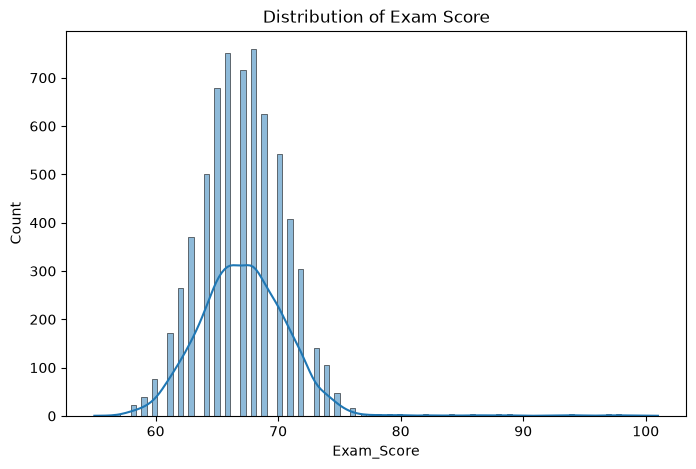

In [19]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df_clean, x="Exam_Score", kde=True)
plt.title("Distribution of Exam Score")
plt.show()


**Nhận xét Q1:**  
Biểu đồ phân phối của cột Exam_Score mang hình dáng của phân phối chuẩn (chuông Gauss), với phần lớn điểm số tập trung dày đặc trong khoảng từ 63 đến 72 điểm. Đường cong mật độ (KDE) thể hiện sự đối xứng rõ rệt ở vùng trung tâm. Đồng thời, biểu đồ cũng phản ánh sự tồn tại của giá trị ngoại lai rất nhỏ nằm ở mốc vượt quá 100 điểm


## Question 2 — Học nhiều hơn có đồng nghĩa điểm cao hơn?

Vẽ `Hours_Studied` vs `Exam_Score`.


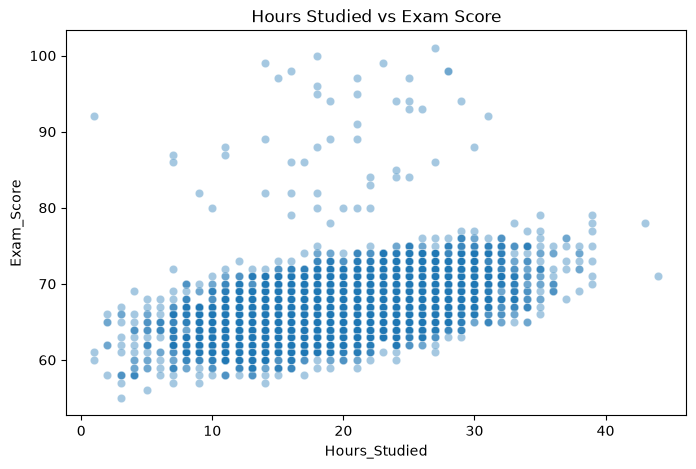

In [20]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_clean, x="Hours_Studied", y="Exam_Score", alpha=0.4)
plt.title("Hours Studied vs Exam Score")
plt.show()


**Nhận xét Q2:**  
Biểu đồ scatter plot thể hiện xu hướng điểm số (Exam_Score) tăng nhẹ khi số giờ học (Hours_Studied) tăng lên, tuy nhiên mức độ phân tán của các điểm dữ liệu khá rộng. Điều này cho thấy số giờ học có mối quan hệ đồng biến nhưng không phải là yếu tố quyết định duy nhất chi phối kết quả thi. Cần lưu ý rằng tương quan không đồng nghĩa với nhân quả, vì điểm số còn chịu ảnh hưởng từ nhiều yếu tố khác như chuyên cần, năng lực cá nhân hoặc phương pháp học tập.

> Lưu ý: tương quan không đồng nghĩa nhân quả.


## Question 3 — `Attendance` hay `Hours_Studied` trông hữu ích hơn?

Vẽ `Attendance` vs `Exam_Score`, sau đó so sánh với biểu đồ trước.


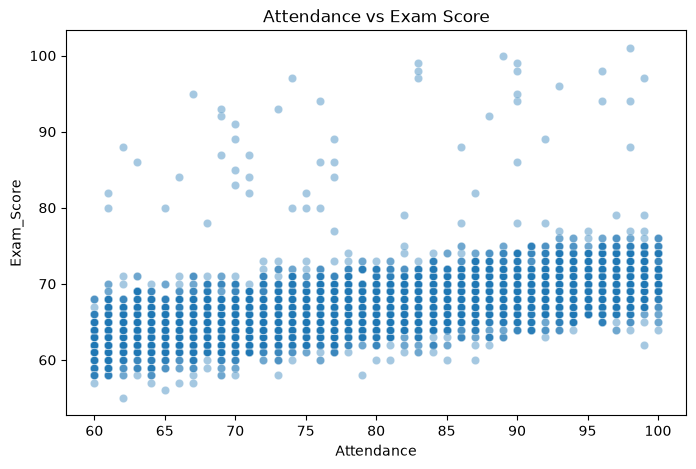

,Hours_Studied,Attendance,Previous_Scores,Exam_Score
Hours_Studied,1.000000,-0.009908,0.024846,0.445455
Attendance,-0.009908,1.000000,-0.020186,0.581072
Previous_Scores,0.024846,-0.020186,1.000000,0.175079
Exam_Score,0.445455,0.581072,0.175079,1.000000


In [21]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_clean, x="Attendance", y="Exam_Score", alpha=0.4)
plt.title("Attendance vs Exam Score")
plt.show()

corr_cols = ["Hours_Studied", "Attendance", "Previous_Scores", "Exam_Score"]
display(df_clean[corr_cols].corr())


**Nhận xét Q3:**  
Biểu đồ scatter plot kết hợp với bảng ma trận tương quan cho thấy tỷ lệ chuyên cần (Attendance) có mối quan hệ đồng biến khá mạnh với điểm thi (Exam_Score). Hệ số tương quan giữa hai biến này đạt mức khoảng 0.58, cao hơn cả yếu tố số giờ học. Điều này chứng minh rằng việc đi học đầy đủ và chuyên cần trên lớp đóng vai trò là một trong những nhân tố quan trọng nhất ảnh hưởng trực tiếp đến kết quả thi cuối kỳ của học sinh

## Question 4 — Các mức `Motivation_Level` có phân bố `Exam_Score` giống nhau không?

Chọn biểu đồ phù hợp cho biến categorical/ordinal.


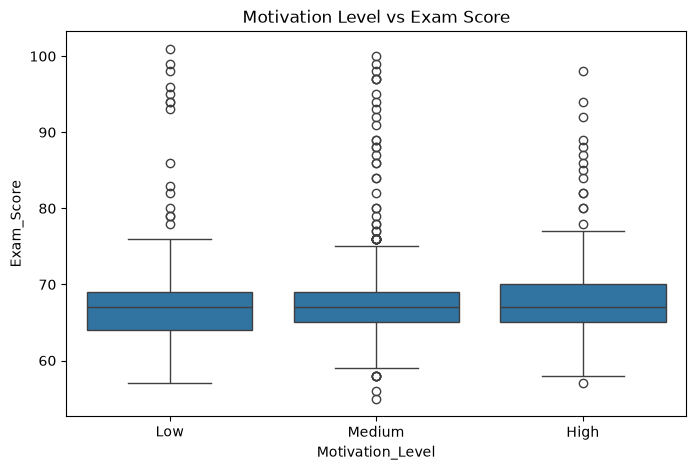

In [22]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean, x="Motivation_Level", y="Exam_Score")
plt.title("Motivation Level vs Exam Score")
plt.show()


**Nhận xét Q4:**  
Biểu đồ boxplot so sánh phân phối điểm thi giữa các mức độ động lực (Motivation_Level gồm Low, Medium, High) cho thấy sự chênh lệch về điểm số trung thất giữa các nhóm là không đáng kể, các khoảng phân vị (IQR) hầu như chồng chéo lên nhau. Điều này cho thấy mức độ động lực tự báo cáo nhìn chung ít tạo ra sự khác biệt lớn trực tiếp đối với điểm số tập trung của học sinh trong tập dữ liệu này.
**Có thể kết luận quan hệ nhân quả không? Vì sao?**  
Không thể kết luận quan hệ nhân quả. Vì đây chỉ là phân tích tương quan/thống kê mô tả trên dữ liệu quan sát (observational data), không phải từ một thí nghiệm kiểm soát ngẫu nhiên (controlled experiment); điểm số có thể bị chi phối bởi nhiều yếu tố nhiễu ẩn khác (như năng lực nền tảng, thời gian tự học, điều kiện gia đình) chứ không chỉ riêng mức độ động lực.


# Final — Data Readiness Report

Hoàn thiện báo cáo như một thành viên của **DNU Learning Analytics Lab**.

## 1. Bài toán

Chúng tôi muốn dự đoán điểm thi cuối kỳ của học sinh dựa trên các yếu tố về thời gian học tập, chuyên cần, điều kiện sinh hoạt và môi trường học tập.

## 2. Target

Exam_Score (Dạng bài toán Hồi quy - Regression)

## 3. Features dự kiến

Các biến số và phân loại bao gồm: Hours_Studied, Attendance, Parental_Involvement, Access_to_Resources, Extracurricular_Activities, Sleep_Hours, Previous_Scores, Motivation_Level, Internet_Access, Tutoring_Sessions, Family_Income, Teacher_Quality, School_Type, Peer_Influence, Physical_Activity, Learning_Disabilities, Parental_Education_Level, Distance_from_Home, Gender

## 4. Vấn đề dữ liệu đã phát hiện

- Có giá trị thiếu (NaN) tại 3 cột: Teacher_Quality, Parental_Education_Level, và Distance_from_Home
- Xuất hiện giá trị ngoại lai nhẹ ở biến mục tiêu (Exam_Score) với mốc 101.0 (vượt quá mức tối đa 100)
- Các biến dạng phân loại (object) chưa được chuyển đổi về kiểu dữ liệu phù hợp (Ordinal / One-Hot Encoding) để đưa vào mô hình máy học

## 5. Cách xử lý đã chọn

- Missing values: Sử dụng phương pháp điền giá trị xuất hiện nhiều nhất (Mode imputation) cho các cột phân loại bị thiếu
- Outliers: Giữ nguyên giá trị ngoại lai 101.0 của Exam_Score (hoặc giới hạn về 100) vì đây là biên độ sai lệch rất nhỏ và không phải lỗi hệ thống nghiêm trọng

## 6. Ba pattern đáng chú ý từ EDA

1. Tỷ lệ chuyên cần (Attendance) có hệ số tương quan đồng biến mạnh nhất với điểm thi (Exam_Score), đạt mức khoảng 0.58
2. Thời gian học tập (Hours_Studied) có quan hệ đồng biến với điểm số nhưng phân tán rộng, tương quan đạt mức trung bình (~0.45)
3. Mức độ động lực (Motivation_Level) hay các yếu tố như số giờ ngủ ít tạo ra sự khác biệt rõ rệt hoặc tương quan trực tiếp lớn đến phân phối điểm thi trung tâm

## 7. Dataset đã sẵn sàng cho modeling chưa?

**Yes / Not yet:** Not yet

**Giải thích:**  
Dù dữ liệu đã được xử lý các giá trị thiếu và kiểm tra phân phối cơ bản, tập dữ liệu vẫn ở dạng thô chứa các cột chuỗi (object). Để huấn luyện mô hình machine learning, chúng ta vẫn cần thực hiện các bước tiền xử lý tiếp theo như mã hóa biến phân loại (Encoding) và chuẩn hóa dữ liệu số (Scaling)

---

## Câu hỏi kết thúc

Nếu bước tiếp theo là huấn luyện một mô hình từ các feature hiện có, còn vấn đề preprocessing nào chúng ta chưa giải quyết?

Vấn đề chưa giải quyết là Mã hóa biến phân loại (Categorical Encoding) và Chuẩn hóa dữ liệu số (Feature Scaling). Các thuật toán máy học không thể trực tiếp xử lý các cột dạng chữ (object như Parental_Involvement, School_Type, v.v.), đồng thời các đặc trưng số cũng cần được đưa về cùng một khoảng giá trị để đảm bảo độ ổn định và tối ưu hiệu suất cho mô hình
